# Hit-Generation by Fragment-Based Molecular Optimization

In [1]:
#!pip install pyTDC

In [2]:
#!pip install safe-mol datamol pandas numpy rdkit msal 2>/dev/null | tail -n 1

In [3]:
#!pip install msal

In [4]:
from nv_genmol.optimizer import MolecularOptimizer
from nv_genmol.library import Library
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.oracle import Oracle

import pandas as pd
import safe as sf


## Library

#### Read molecular library of FDA-approved drugs with 20~30 heavy atoms 

In [5]:
mol_library = pd.read_csv('../../data/interim/genmol/BCS-CN20332_R1_testmulti.csv')
mol_library

,smiles,score
0,CCC1CCC1CC(=O)NCCC(=O)OC,0.699
1,COC(=O)CCNC(=O)COC(C)(C)C,0.680
2,COC(=O)CCNC(=O)C[Rg+],0.626
3,CCCC(=O)NCCC(=O)OC,0.615
4,CCC(=O)NCCC(=O)OC,0.591
...,...,...
332,COC(=O)CCNC(=O)CCC[Se]c1cc(Cl)cc(Cl)c1,0.416
333,COC(=O)CCNC(=O)[Cl+3](C)c1cc(Cl)cc(Cl)c1,0.392
334,COC(=O)CCNCC(N=C([O-])C1CC1)c1cc(Cl)cc(Cl)c1,0.335
335,COC(=O)CCNCCN=C(O)c1cn(-c2cc(Cl)cc(Cl)c2)nc1N,0.271


## calc score with the right scorer 

In [6]:
from nv_genmol.by_scorer_new import MoleculeScorer

hsec_scorer = MoleculeScorer.create_scorer( reference_smiles = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1",
                                            use_qsar_hsec=True,
                                            use_qsar_aih=False,
                                            use_qed = False,
                                            use_similarity=False,
                                            similarity_weight=1.0,
                                            similarity_threshold=1.0)

results = hsec_scorer.score(mol_library['smiles'])

#~now scoring~#
Prediction failed for ID 25: Unknown error
No prediction found for ID 25
Prediction failed for ID 40: Unknown error
No prediction found for ID 40
#~Done scoring~#


**change the Scorer HERE if needed**

In [7]:
#drop original score column
mol_library.drop('score',axis=1,inplace=True)

#create new score column with QSAR scores
mol_library['score'] = results.qsar_hsec_scores # combined_scores / qsar_hsec_scores
mol_library.sort_values(by='score',ascending=False, inplace=True)
print(len(mol_library))
mol_library.head()

337


,smiles,score
279,COC(=O)CCNC(=O)C1=CCN(c2cc(Cl)cc(Cl)c2)C1,118.87
234,COC(=O)CCNC1=C[N+]=[NH+]C(c2cc(Cl)cc(Cl)c2)=C1,115.44
161,COC(=O)CCNC(=O)N1CC(Nc2cc(Cl)cc(Cl)c2)C1,103.19
272,COC(=O)CCNC1=CC=C[N+]=C1c1cc(Cl)cc(Cl)c1,102.88
330,C=CC(CNCCC(=O)OC)c1cc(Cl)cc(Cl)c1,97.57


#### Initiate fragment library from known molecules

In [10]:
library = Library(max_fragments = 1000)

In [11]:
molecules = {r['smiles']:r['score'] for idx, r in mol_library.iterrows()}
library.update(molecules)

min score:0.0


In [12]:
#library.fragments
library.export(2)

['C16CCN(NCCC3=O)CC1.C2(=O)CC4.CO2.N45.C56.O3C',
 'c17cc(Cl)cc(Cl)c1.c16ncc7cn1.C5CC3=O.O3CN4.C46=O.CN5']

## Oracle

In [13]:
#oracle = Oracle(score = Oracle.RDKitScore('SA'))
# Create an Oracle with HSEC scoring
oracle = Oracle(score=Oracle.HSECScore('hsec', ref_smiles="COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1")) #hsec / comp

In [14]:
# test eval with the original seed 
oracle.evaluate(['COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1'])

#~now scoring~#
#~Done scoring~#


{'COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1': 177.91}

## Generator

In [15]:
GENMOL_HOST = 'http://127.0.0.1:8083'
generator = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")

### Test generator

In [16]:
generator.inference(
    smiles = 'c13cc(Cl)cc(Cl)c1.[*{8-20}]',
    num_molecules = 5,
    temperature = 2.0, #1.5
    noise = 1.0 #2.0
)

[{'smiles': 'Clc1cc(Cl)cc(-c2cnc[nH]2)c1', 'score': 0.772},
 {'smiles': '[CH2]CCCCNc1cc(Cl)cc(Cl)c1', 'score': 0.74},
 {'smiles': 'Clc1cc(Cl)cc(-c2cscn2)c1', 'score': 0.718},
 {'smiles': 'Nc1cc(Cl)cc(Cl)c1', 'score': 0.583}]

In [17]:
generator.produce(['CCC1CCC1CC(=O)NCCC(=O)OC'], 1)

['CSc1csc(C)c1-c1cccc(O)c1']

## Optimizer

In [19]:
optimizer = MolecularOptimizer(library = library, oracle = oracle, generator = generator)

In [34]:
#data = []

def eval():
    best = library.molecules.score[0]
    mean = library.molecules.head(50)['score'].mean()
    std = library.molecules.head(50)['score'].std()
    print("BEST", best, "MEAN", mean, "STD", std)
    data.append([best, mean, std])

eval()

for i in range(100):
    optimizer.run(iterations = 10, num_mutate = 50)
    eval()

BEST 173.19 MEAN 134.02980000000002 STD 11.006935010552697
#~now scoring~#
#~Done scoring~#
min score:104.86
#~now scoring~#
#~Done scoring~#
min score:104.86
#~now scoring~#
#~Done scoring~#
min score:104.86
#~now scoring~#
#~Done scoring~#
min score:104.86
#~now scoring~#
#~Done scoring~#
min score:105.05
#~now scoring~#
#~Done scoring~#
min score:105.05
#~now scoring~#
#~Done scoring~#
min score:105.19
#~now scoring~#
#~Done scoring~#
min score:105.23
#~now scoring~#
#~Done scoring~#
min score:105.23
#~now scoring~#
#~Done scoring~#
min score:105.31
BEST 173.19 MEAN 134.05920000000003 STD 10.981177000965362
#~now scoring~#
#~Done scoring~#
min score:105.41
#~now scoring~#
#~Done scoring~#
min score:105.41
#~now scoring~#
#~Done scoring~#
min score:105.41
#~now scoring~#
#~Done scoring~#
min score:105.48
#~now scoring~#
#~Done scoring~#
min score:105.48
#~now scoring~#
#~Done scoring~#
min score:105.48
#~now scoring~#
#~Done scoring~#
min score:105.48
#~now scoring~#
#~Done scoring~#

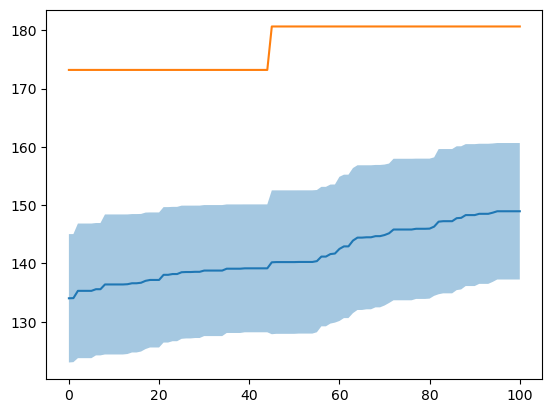

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data, columns = ['best', 'mean', 'std'])

plt.fill_between(df.index, df['mean']-df['std'], df['mean'] + df['std'], alpha=0.4)
plt.plot(df['mean'])
plt.plot(df['best'])

In [22]:
df.shape

(26, 3)

# Outputs

In [30]:
df_safe = library.molecules
df_safe.head()

,smiles,score
0,COC(=O)[NH+]1CC(NC(=O)Cc2cc(Cl)cc(N3CC=C(C(=O)...,173.19
1,C=C(CC(=O)N(C)CC)c1cc(Cl)cc(NC(=O)C2=CCN(CC(=O...,170.17
2,COC(=O)N1CC(NC(=O)CC(=O)Oc2cc(Cl)cc(N3CC=C(C(=...,155.18
3,C=C(c1cc(O)cc(Cl)c1)c1cc(C(=O)C(=O)CCCC(=O)OC2...,153.33
4,C=C(c1cc(Cl)cc(NC(=O)C2=CCN(CC(=O)C3(C4CN(C(=O...,149.02


In [31]:
len(df_safe)

853

COC(=O)[NH+]1CC(NC(=O)Cc2cc(Cl)cc(N3CC=C(C(=O)Cl)C3)c2)C1


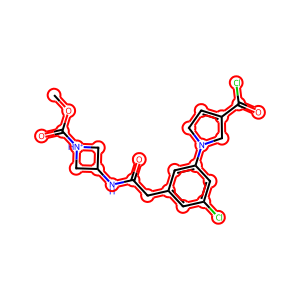

In [32]:
import safe as sf
print(df_safe.iloc[0,0])
sf.to_image(df_safe.iloc[0,0])


In [31]:
type(df_safe)

pandas.core.frame.DataFrame

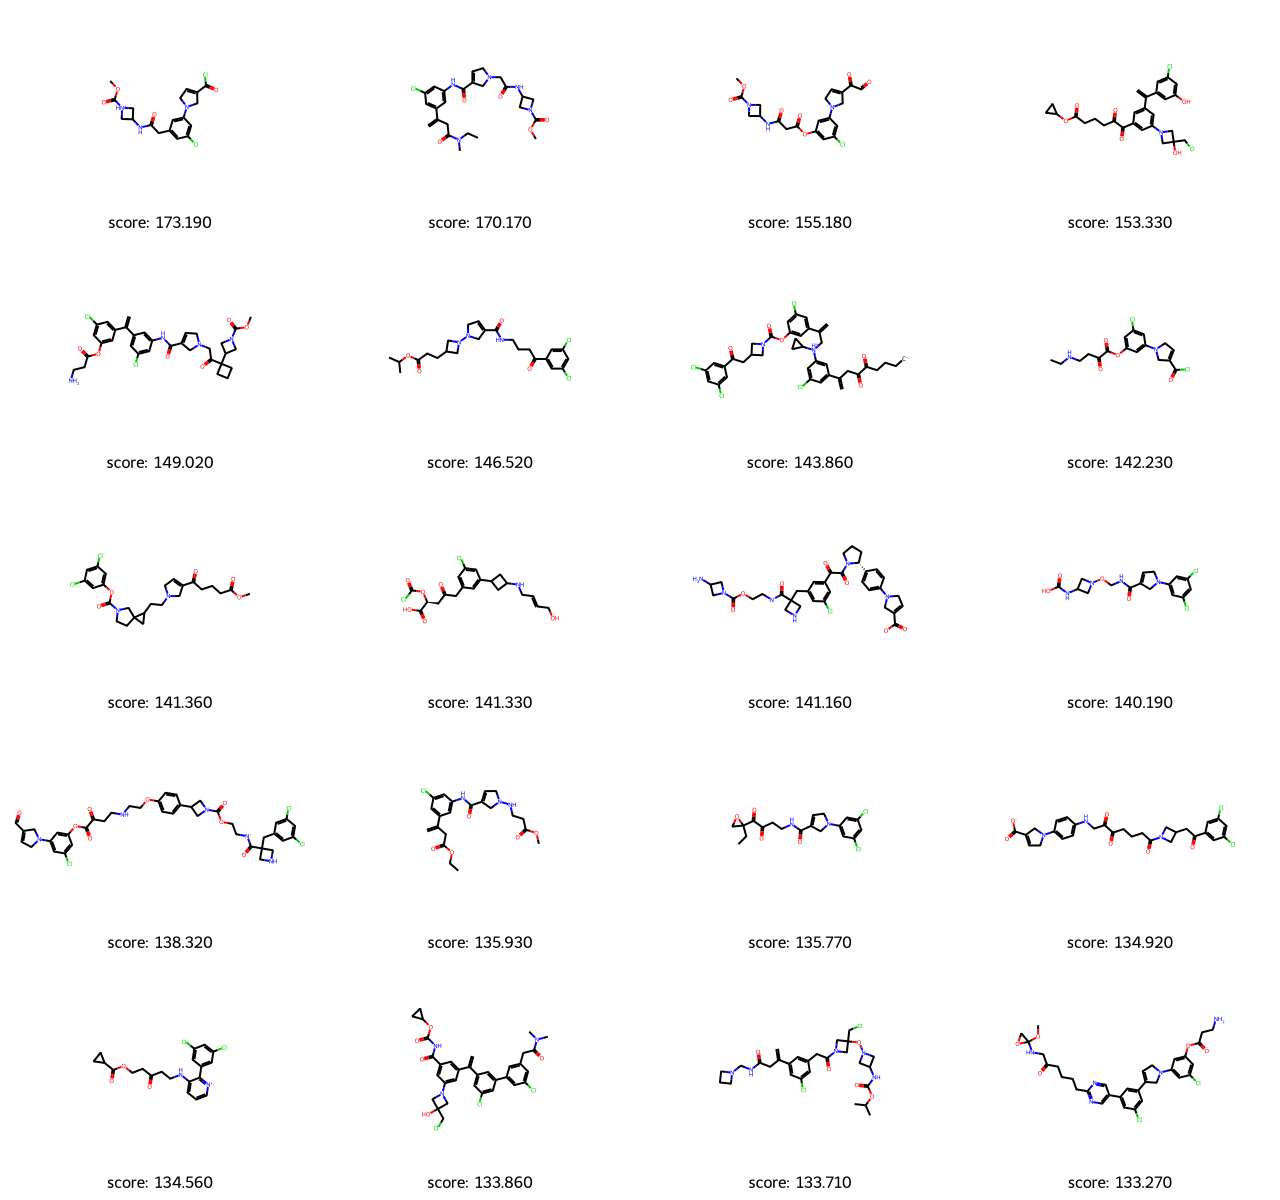

In [33]:
from rdkit.Chem import Draw
from rdkit import Chem
#select first 20
df_to_show = df_safe.iloc[0:20].copy()

#vis
ms = [Chem.MolFromSmiles(row['smiles']) for index, row in df_to_show.iterrows()]
legends = ['score: {:.3f}'.format(row['score']) for index, row in df_to_show.iterrows()]
#['score ' + str(row['score']) for index, row in df_to_show.iterrows()]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(320, 240), legends=legends)
